# تحليل الطلب على توصيل الطعام

**سؤال العميل:** يقوم مديرو المراكز بطلب المكونات سريعة التلف أسبوعيًا بناءً على تقديرهم، مما يؤدي إلى هدر بعض الطعام في بعض المراكز بينما ينفد في مراكز أخرى. يستخدم قسم التسويق عروض البريد الإلكتروني الترويجية، وميزات الصفحة الرئيسية، وتغييرات الأسعار، ولكن لا أحد يعلم أيًّا من هذه العوامل يؤثر على الطلب، أو مقدار هذا التأثير.


**نطاق هذه المذكرة:** إعداد البيانات وقرارات الجودة، ومؤشرات الأداء الرئيسية، وأسئلة التحليل الستة، واختبارات العروض الترويجية والخصومات، وتقلبات الطلب، وتوقعات لمدة عشرة أسابيع. كل رقم مذكور في التقرير والعرض التقديمي مُدرج في خلية منفصلة في هذه المذكرة.


**قاعدة قراءة جميع النتائج أدناه:** هذه بيانات رصدية. لم يتم توزيع العروض الترويجية عشوائيًا، لذا فإن أي اختلاف في الطلبات بين الأسابيع التي شهدت عروضًا ترويجية والأسابيع التي لم تشهدها يُعد ارتباطًا. لم تُستخدم كلمة "يسبب" في أي مكان دون وجود تجربة تدعمها.

In [25]:
import json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from scipy import stats

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

# Resolve paths from either the project root or the notebooks directory.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"
if not (RAW / "train.csv").exists() and (ROOT / "train.csv").exists():
    RAW = ROOT
FIG, DOCS, PBI = ROOT/"reports/figures", ROOT/"docs", ROOT/"powerbi"
for p in (FIG, DOCS, PBI): p.mkdir(parents=True, exist_ok=True)
missing = [f for f in ("train.csv", "test.csv", "meal_info.csv", "fulfilment_center_info.csv") if not (RAW/f).exists()]
print("reading from:", RAW, "\nwriting to:  ", ROOT)

# Validated categorical palette (dataviz reference instance); grey for context marks
BLUE, ORANGE, AQUA, YELLOW, GREY, INK, INK2 = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#b9b8b2", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#8a8984", "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "lines.linewidth": 2,
})
import sys, sklearn, matplotlib, scipy
print("python", sys.version.split()[0], "| pandas", pd.__version__, "| scipy", scipy.__version__, "| matplotlib", matplotlib.__version__, "| sklearn", sklearn.__version__)
RESULTS = {}   # every headline number lands here and is exported for the report/deck

reading from: data/raw
writing to:   project root
python 3.14.8 | pandas 3.0.6 | scipy 1.18.1 | matplotlib 3.11.2 | sklearn 1.9.1


In [26]:
# Paths are initialized in the setup cell above.

## 1. Load and join the three files

In [27]:

import pandas as pd
import matplotlib.pyplot as plt
train  = pd.read_csv('../data/raw/train.csv')
meals  = pd.read_csv('../data/raw/meal_info.csv')
centers= pd.read_csv('../data/raw/fulfilment_center_info.csv')
test   = pd.read_csv('../data/raw/test.csv')
for n, d in [("train", train), ("meals", meals), ("centers", centers), ("test", test)]:
    print(f"{n:8s} rows={len(d):>8,}  cols={d.shape[1]}")

rows0, orders0 = len(train), train["num_orders"].sum()
df = (train.merge(meals, on="meal_id", how="left", validate="many_to_one")
           .merge(centers, on="center_id", how="left", validate="many_to_one"))
print(f"\nafter join: rows={len(df):,}  orders={df['num_orders'].sum():,}")
assert len(df) == rows0 and df["num_orders"].sum() == orders0, "join changed rows or orders"
assert df[["category", "center_type"]].notna().all().all(), "unmatched keys"
print("join check passed: row count and order total unchanged, every key matched")

train    rows= 456,548  cols=9
meals    rows=      51  cols=3
centers  rows=      77  cols=5
test     rows=  32,573  cols=8

after join: rows=456,548  orders=119,557,485
join check passed: row count and order total unchanged, every key matched


## 2. Data quality checks

In [28]:
checks = {}
RESULTS = {}   # every headline number lands here and is exported for the report/deck
checks["missing_values"] = int(df.isna().sum().sum())
checks["duplicate_rows"] = int(df.duplicated().sum())
checks["duplicate_week_center_meal"] = int(df.duplicated(["week", "center_id", "meal_id"]).sum())

markup = df["checkout_price"] > df["base_price"]
disc_raw = (df["base_price"] - df["checkout_price"]) / df["base_price"]
checks["checkout_above_base"] = int(markup.sum())
checks["checkout_above_base_gt20pct"] = int((disc_raw < -0.20).sum())

q1, q3 = df["num_orders"].quantile([.25, .75])
iqr_cut = q3 + 1.5 * (q3 - q1)
checks["orders_iqr_outliers"] = int((df["num_orders"] > iqr_cut).sum())
p999 = df["num_orders"].quantile(.999)
checks["orders_above_p99_9"] = int((df["num_orders"] > p999).sum())

span = df.groupby(["center_id", "meal_id"])["week"].agg(["min", "max", "count"])
span["gaps"] = span["max"] - span["min"] + 1 - span["count"]
checks["center_meal_pairs"] = len(span)
checks["pairs_with_missing_weeks"] = int((span["gaps"] > 0).sum())
checks["missing_pair_weeks"] = int(span["gaps"].sum())

weekly_rows = df.groupby("week").size()
checks["min_num_orders"] = int(df["num_orders"].min())

for k, v in checks.items(): print(f"{k:32s} {v:>10,}")
print(f"\nIQR upper fence = {iqr_cut:,.0f} orders; 99.9th percentile = {p999:,.0f}")
print("share of rows with checkout > base:", f"{markup.mean():.1%}",
      "| median markup on those rows:", f"{-disc_raw[markup].median():.2%}")
RESULTS["quality"] = checks

missing_values                            0
duplicate_rows                            0
duplicate_week_center_meal                0
checkout_above_base                 116,101
checkout_above_base_gt20pct             233
orders_iqr_outliers                  32,937
orders_above_p99_9                      457
center_meal_pairs                     3,597
pairs_with_missing_weeks              2,129
missing_pair_weeks                   40,548
min_num_orders                           13

IQR upper fence = 729 orders; 99.9th percentile = 4,138
share of rows with checkout > base: 25.4% | median markup on those rows: 0.37%


**ما تُظهره عمليات التدقيق:** لا توجد قيم مفقودة ولا صفوف مكررة لوجبات المراكز الأسبوعية. ربع الصفوف تحتوي على سعر شراء أعلى من السعر الأساسي، لكن متوسط ​​الفرق في هذه الصفوف يبلغ حوالي 0.4%، وهو ما يبدو كتقريب أو رسوم إضافية بسيطة وليس خطأً؛ بضع مئات فقط من الصفوف تتجاوز هامش ربح 20%. عدد الطلبات منحرف بشدة نحو اليمين، لذا تشير قاعدة المدى الربيعي إلى حوالي 7% من الصفوف، وهي خاصية للتوزيع وليست دلالة على سوء البيانات. أصغر عدد طلبات في الملف بأكمله هو 13، مما يشير إلى احتمال حذف أو تقليل عدد الطلبات الأسبوعية الصغيرة جدًا قبل مشاركة البيانات؛ لا يمكن التحقق من ذلك، وهو مُدرج كأحد القيود. العديد من أزواج الوجبات والمراكز تحتوي على أسابيع مفقودة ضمن نطاقها النشط.

In [29]:

decisions = pd.DataFrame([
    ["Missing values", checks["missing_values"], "No action", "None found."],
    ["Duplicate rows / duplicate week-centre-meal keys", checks["duplicate_week_center_meal"], "No action", "Key is unique, so the join is safe."],
    ["checkout_price > base_price", checks["checkout_above_base"], "Keep; discount computed as signed value",
     "Median markup ≈0.4%: plausible surcharge/rounding. Negative discount is kept, not clipped, so price rises stay visible in the discount test."],
    ["Markup > 20%", checks["checkout_above_base_gt20pct"], "Keep, flag (price_flag=1)",
     "Too few to move any result; flagged so Power BI can filter them."],
    ["Order outliers (IQR rule)", checks["orders_iqr_outliers"], "Keep",
     "Right-skewed demand; spikes are exactly what safety stock must cover. Robust methods (medians, Mann-Whitney, Spearman) used instead of removal."],
    ["Extreme orders > 99.9th pct", checks["orders_above_p99_9"], "Keep, flag (extreme_flag=1)", "Checked in sensitivity analysis; conclusions unchanged."],
    ["Missing weeks inside a pair's active span", checks["missing_pair_weeks"], "Do not impute",
     "A missing week may mean zero sales or meal not offered; the data cannot tell which. Volatility uses observed weeks; forecast lags use exact week matches."],
    ["Minimum order count = 13", 1, "Document as limitation", "Possible floor/truncation of small counts by the data provider."],
], columns=["Issue", "Count", "Decision", "Reason"])
decisions.to_csv(DOCS/"cleaning_decisions.csv", index=False)
try:
    md_table = decisions.to_markdown(index=False)      # needs the tabulate package
except ImportError:
    md_table = decisions.to_string(index=False)
(DOCS/"cleaning_decisions.md").write_text("# Cleaning decisions\n\n" + md_table, encoding="utf-8")
decisions

,Issue,Count,Decision,Reason
0,Missing values,0,No action,None found.
1,Duplicate rows / duplicate week-centre-meal keys,0,No action,"Key is unique, so the join is safe."
2,checkout_price > base_price,116101,Keep; discount computed as signed value,Median markup ≈0.4%: plausible surcharge/round...
3,Markup > 20%,233,"Keep, flag (price_flag=1)",Too few to move any result; flagged so Power B...
4,Order outliers (IQR rule),32937,Keep,Right-skewed demand; spikes are exactly what s...
5,Extreme orders > 99.9th pct,457,"Keep, flag (extreme_flag=1)",Checked in sensitivity analysis; conclusions u...
6,Missing weeks inside a pair's active span,40548,Do not impute,A missing week may mean zero sales or meal not...
7,Minimum order count = 13,1,Document as limitation,Possible floor/truncation of small counts by t...


## 3. Derived fields and KPIs

In [30]:
df["revenue"] = df["checkout_price"] * df["num_orders"]
df["discount_pct"] = disc_raw
df["email"] = df["emailer_for_promotion"]
df["home"] = df["homepage_featured"]
df["any_promo"] = ((df["email"] + df["home"]) > 0).astype(int)
df["promo_type"] = np.select([(df.email == 1) & (df.home == 1), df.email == 1, df.home == 1],
                             ["Email + Homepage", "Email only", "Homepage only"], "No promotion")
df["price_flag"] = (disc_raw < -0.20).astype(int)
df["extreme_flag"] = (df["num_orders"] > p999).astype(int)
print(f"rows after derivation: {len(df):,}")

weekly = df.groupby("week").agg(orders=("num_orders", "sum"), revenue=("revenue", "sum")).reset_index()
kpi = {
    "total_orders": int(df["num_orders"].sum()),
    "weeks": int(df["week"].nunique()),
    "avg_weekly_orders": float(weekly["orders"].mean()),
    "total_revenue": float(df["revenue"].sum()),
    "avg_discount_pct": float(df["discount_pct"].mean()),
    "share_rows_email": float(df["email"].mean()),
    "share_rows_home": float(df["home"].mean()),
    "share_rows_any_promo": float(df["any_promo"].mean()),
    "centers": int(df["center_id"].nunique()), "meals": int(df["meal_id"].nunique()),
}
RESULTS["kpi"] = kpi
pd.Series(kpi)

rows after derivation: 456,548


total_orders              119,557,485.000
weeks                             145.000
avg_weekly_orders             824,534.379
total_revenue          31,922,771,040.110
avg_discount_pct                    0.057
share_rows_email                    0.081
share_rows_home                     0.109
share_rows_any_promo                0.148
centers                            77.000
meals                              51.000
dtype: float64

## س1. كيف يتغير إجمالي الطلب من أسبوع لآخر؟

In [31]:
weekly["roll4"] = weekly["orders"].rolling(4, center=True).mean()
weekly["wow_pct"] = weekly["orders"].pct_change()
cv_week = weekly["orders"].std() / weekly["orders"].mean()
rho_trend, p_trend = stats.spearmanr(weekly["week"], weekly["orders"])
first, last = weekly.head(26)["orders"].mean(), weekly.tail(26)["orders"].mean()
low = weekly.nsmallest(1, "orders").iloc[0]; high = weekly.nlargest(1, "orders").iloc[0]
q1r = dict(cv_weekly_total=cv_week, spearman_week_trend=rho_trend, p_trend=p_trend,
           first26_avg=first, last26_avg=last, change_first_last=last/first-1,
           median_abs_wow=float(weekly["wow_pct"].abs().median()),
           low_week=int(low.week), low_orders=int(low.orders), high_week=int(high.week), high_orders=int(high.orders),
           weeks_above_1m=int((weekly.orders > 1e6).sum()))
RESULTS["q1"] = q1r
for k, v in q1r.items(): print(f"{k:22s} {v:,.4f}" if isinstance(v, float) else f"{k:22s} {v:,}")

cv_weekly_total        0.1524
spearman_week_trend    0.1697
p_trend                0.0412
first26_avg            771,472.6154
last26_avg             816,146.9615
change_first_last      0.0579
median_abs_wow         0.0856
low_week               62
low_orders             380,065
high_week              48
high_orders            1,303,457
weeks_above_1m         13


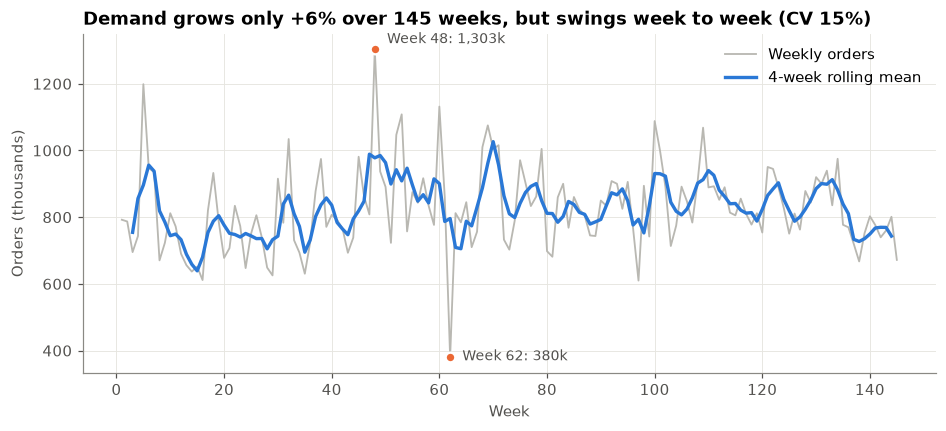

In [32]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(weekly.week, weekly.orders/1e3, color=GREY, lw=1.2, label="Weekly orders")
ax.plot(weekly.week, weekly.roll4/1e3, color=BLUE, lw=2.2, label="4-week rolling mean")
for r, va in [(low, "top"), (high, "bottom")]:
    ax.scatter(r.week, r.orders/1e3, s=40, color=ORANGE, zorder=3, edgecolor="white", lw=1.5)
    ax.annotate(f"Week {int(r.week)}: {r.orders/1e3:,.0f}k", (r.week, r.orders/1e3), xytext=(8, -2 if va=="top" else 4),
                textcoords="offset points", color=INK2, fontsize=9)
ax.set_title(f"Demand grows only {q1r['change_first_last']:+.0%} over 145 weeks, but swings week to week (CV {cv_week:.0%})")
ax.set_xlabel("Week"); ax.set_ylabel("Orders (thousands)"); ax.legend(frameon=False, loc="upper right")
fig.savefig(FIG/"01_weekly_demand.png"); plt.show()

Demand has no strong long-run trend: the average of the last 26 weeks is close to the first 26. The week-to-week swing is the operational issue. The weekly total has a coefficient of variation near 15%, and week 62 falls to less than half of a normal week without a matching fall in the number of rows. Without real dates, this drop cannot be tied to a holiday, outage or data-collection problem.

## س2. ما هي الفئات والوجبات التي تشكل الجزء الأكبر من الطلب؟

In [33]:
cat = df.groupby("category").agg(orders=("num_orders", "sum"), revenue=("revenue", "sum"), meals=("meal_id", "nunique")).sort_values("orders", ascending=False)
cat["share"] = cat.orders / cat.orders.sum(); cat["cum_share"] = cat.share.cumsum()
meal = df.groupby(["meal_id", "category", "cuisine"]).agg(orders=("num_orders", "sum"), revenue=("revenue", "sum")).reset_index().sort_values("orders", ascending=False)
meal["share"] = meal.orders / meal.orders.sum(); meal["cum_share"] = meal.share.cumsum()
n_cat80 = int((cat.cum_share < 0.80).sum() + 1); n_meal80 = int((meal.cum_share < 0.80).sum() + 1)
cuis = df.groupby("cuisine")["num_orders"].sum().sort_values(ascending=False); cuis = cuis / cuis.sum()
RESULTS["q2"] = dict(n_categories=len(cat), n_cat80=n_cat80, cat80=list(cat.index[:n_cat80]),
                     top_category=cat.index[0], top_category_share=float(cat.share.iloc[0]),
                     n_meals=len(meal), n_meal80=n_meal80, top10_meal_share=float(meal.share.head(10).sum()),
                     top_meal=int(meal.meal_id.iloc[0]), top_meal_cat=meal.category.iloc[0], top_meal_share=float(meal.share.iloc[0]),
                     cuisine_share={k: float(v) for k, v in cuis.items()})
print(f"{n_cat80} of {len(cat)} categories and {n_meal80} of {len(meal)} meals make 80% of orders")
cat

5 of 14 categories and 22 of 51 meals make 80% of orders


,orders,revenue,meals,share,cum_share
category,,,,,
Beverages,40480525,"7,347,303,891.230",12,0.339,0.339
Rice Bowl,20874063,"5,881,531,237.410",3,0.175,0.513
Sandwich,17636782,"4,663,426,849.810",3,0.148,0.661
Salad,10944336,"3,032,256,462.860",3,0.092,0.752
Pizza,7383720,"3,955,955,845.370",3,0.062,0.814
Other Snacks,4766293,"1,209,248,401.740",3,0.040,0.854
Starters,4649122,"1,259,443,207.790",3,0.039,0.893
Extras,3984979,"679,012,552.650",3,0.033,0.926
Seafood,2715714,"1,447,748,836.660",3,0.023,0.949


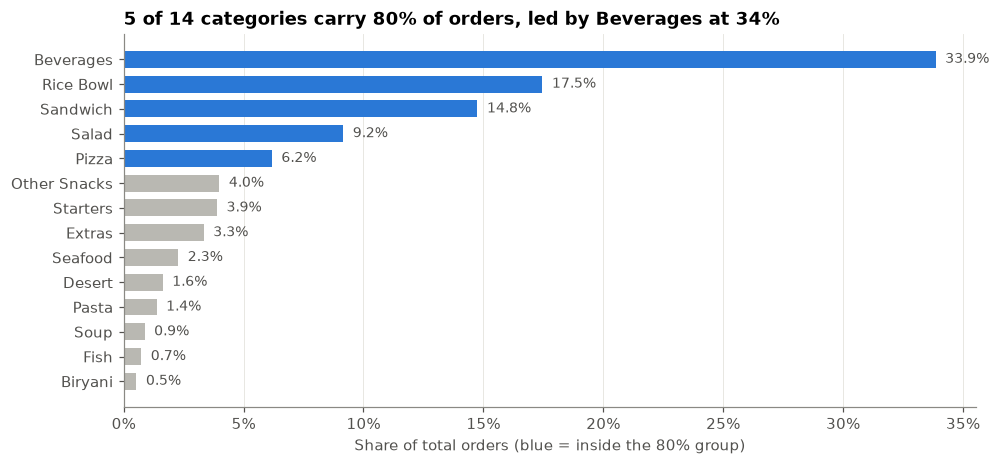

In [34]:
fig, ax = plt.subplots(figsize=(10, 4.4))
c = cat.sort_values("orders")
colors = [BLUE if x in RESULTS["q2"]["cat80"] else GREY for x in c.index]
ax.barh(c.index, c.share*100, color=colors, height=0.68)
for i, (s, nm) in enumerate(zip(c.share, c.index)):
    ax.text(s*100 + 0.4, i, f"{s:.1%}", va="center", fontsize=9, color=INK2)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0)); ax.grid(axis="y", visible=False)
ax.set_title(f"{n_cat80} of {len(cat)} categories carry 80% of orders, led by {cat.index[0]} at {cat.share.iloc[0]:.0%}")
ax.set_xlabel("Share of total orders (blue = inside the 80% group)")
fig.savefig(FIG/"02_category_share.png"); plt.show()

## س3. ما هي المراكز التي تحقق أفضل أداء، وهل يختلف الأداء باختلاف نوع المركز؟

In [35]:
cw = df.groupby(["center_id", "week"])["num_orders"].sum().reset_index()
cen = (cw.groupby("center_id")["num_orders"].mean().rename("avg_weekly_orders").reset_index()
         .merge(centers, on="center_id"))
cen["orders_per_op_area"] = cen.avg_weekly_orders / cen.op_area
cen = cen.sort_values("avg_weekly_orders", ascending=False)
by_type = cen.groupby("center_type").agg(centers=("center_id", "count"), median_weekly=("avg_weekly_orders", "median"),
                                         mean_weekly=("avg_weekly_orders", "mean"), median_op_area=("op_area", "median"),
                                         median_per_area=("orders_per_op_area", "median"))
kw = stats.kruskal(*[g.avg_weekly_orders for _, g in cen.groupby("center_type")])
kw_area = stats.kruskal(*[g.orders_per_op_area for _, g in cen.groupby("center_type")])
rho_area, p_area = stats.spearmanr(cen.op_area, cen.avg_weekly_orders)
top10_share = cen.head(10).avg_weekly_orders.sum() / cen.avg_weekly_orders.sum()
RESULTS["q3"] = dict(top_center=int(cen.center_id.iloc[0]), top_center_weekly=float(cen.avg_weekly_orders.iloc[0]),
                     median_center_weekly=float(cen.avg_weekly_orders.median()), top10_center_share=float(top10_share),
                     kruskal_H=float(kw.statistic), kruskal_p=float(kw.pvalue),
                     kruskal_per_area_p=float(kw_area.pvalue), spearman_area_orders=float(rho_area), p_area=float(p_area),
                     by_type=by_type.reset_index().to_dict(orient="records"))
print(f"Kruskal-Wallis on avg weekly orders by type: H={kw.statistic:.2f}, p={kw.pvalue:.4f}")
print(f"Kruskal-Wallis on orders per op_area by type: p={kw_area.pvalue:.4f}")
print(f"Spearman op_area vs avg weekly orders: rho={rho_area:.2f}, p={p_area:.2g}")
display(by_type); cen.head(10)

Kruskal-Wallis on avg weekly orders by type: H=13.21, p=0.0014
Kruskal-Wallis on orders per op_area by type: p=0.5743
Spearman op_area vs avg weekly orders: rho=0.68, p=7.3e-12


,centers,median_weekly,mean_weekly,median_op_area,median_per_area
center_type,,,,,
TYPE_A,43,"10,007.214","11,063.114",4.000,"2,594.686"
TYPE_B,15,"13,148.517","13,982.633",4.400,"2,629.703"
TYPE_C,19,"7,006.345","7,471.105",3.000,"2,284.550"


,center_id,avg_weekly_orders,city_code,region_code,center_type,op_area,orders_per_op_area
2,13,"29,631.345",590,56,TYPE_B,6.700,"4,422.589"
18,43,"27,036.510",590,56,TYPE_A,5.100,"5,301.277"
0,10,"23,317.366",590,56,TYPE_B,6.300,"3,701.169"
21,52,"21,557.483",685,56,TYPE_B,5.600,"3,849.550"
63,137,"21,499.848",590,56,TYPE_A,4.400,"4,886.329"
31,67,"19,582.710",638,56,TYPE_B,7.000,"2,797.530"
1,11,"19,291.724",679,56,TYPE_A,3.700,"5,213.979"
74,174,"19,259.221",700,56,TYPE_A,7.000,"2,751.317"
53,104,"16,741.669",647,56,TYPE_A,4.500,"3,720.371"
7,24,"16,646.125",614,85,TYPE_B,3.600,"4,623.924"


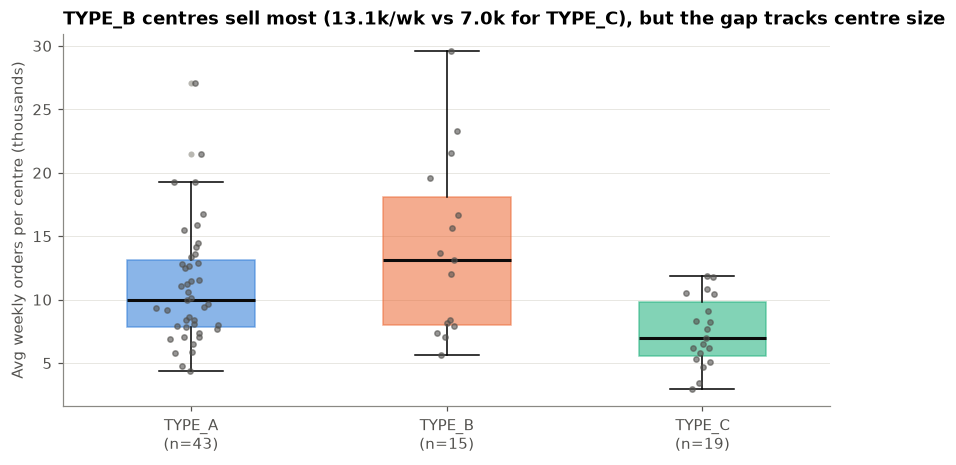

In [36]:
fig, ax = plt.subplots(figsize=(9, 4.4))
types = sorted(cen.center_type.unique())
data = [cen.loc[cen.center_type == t, "avg_weekly_orders"]/1e3 for t in types]
bp = ax.boxplot(data, patch_artist=True, widths=0.5,
                medianprops=dict(color=INK, lw=2), flierprops=dict(marker="o", markersize=4, markerfacecolor=GREY, markeredgecolor="none"))
ax.set_xticks(range(1, len(types)+1), [f"{t}\n(n={len(d)})" for t, d in zip(types, data)])
for patch, col in zip(bp["boxes"], [BLUE, ORANGE, AQUA]): patch.set_facecolor(col); patch.set_alpha(0.55); patch.set_edgecolor(col)
for i, d in enumerate(data, 1):
    ax.scatter(np.random.default_rng(1).normal(i, 0.05, len(d)), d, s=12, color=INK2, alpha=0.6, zorder=3)
tb = by_type.median_weekly
ax.set_title(f"TYPE_B centres sell most ({tb['TYPE_B']/1e3:.1f}k/wk vs {tb['TYPE_C']/1e3:.1f}k for TYPE_C), but the gap tracks centre size")
ax.set_ylabel("Avg weekly orders per centre (thousands)"); ax.grid(axis="x", visible=False)
fig.savefig(FIG/"03_center_type.png"); plt.show()

يُعدّ نوع المركز عاملاً مهماً، لكن جزءاً كبيراً من الفجوة يرتبط بمنطقة التشغيل: فالمراكز الأكبر حجماً تبيع أكثر، وتميل مراكز النوع "ب" إلى أن تكون أكبر. وتُعتبر الطلبات لكل وحدة من منطقة التشغيل معياراً أكثر عدلاً للمقارنة عند تقييم مدير المركز. ويتعامل اختبار كروسكال-واليس مع المراكز الـ 77 كوحدات مستقلة، وهو أمر منطقي هنا؛ إذ يُشير إلى اختلاف توزيعات الأنواع، وليس إلى أن النوع نفسه هو سبب الاختلاف.

## س٤. هل تُساهم العروض الترويجية عبر البريد الإلكتروني وميزات الصفحة الرئيسية في زيادة الطلب، وبأي قدر؟

ثلاثة مستويات، من الأبسط إلى الأكثر تحكمًا. تُجرى جميع المقارنات **ضمن نفس الوجبة في نفس المركز**، لذا لا تتم مقارنة وجبة شائعة في مركز كبير بوجبة متخصصة في مركز صغير.


١. **اختبار مان-ويتني يو لكل زوج**: لكل زوج من المركز والوجبة، مع ٥ أسابيع على الأقل من العروض الترويجية و٥ أسابيع من غير العروض الترويجية، يتم اختبار الأسابيع التي تم فيها العروض الترويجية مقابل الأسابيع التي لم يتم فيها العروض الترويجية. يتم إجراء آلاف الاختبارات، لذا يتم تصحيح قيم p باستخدام طريقة بنجاميني-هوخبيرغ (معدل اكتشاف خاطئ ٥٪).


٢. **الزيادة المجمعة داخل الزوج**: يتم تقسيم كل صف على متوسط ​​الطلبات غير المُروّجة في الزوج؛ يعطي متوسط ​​هذه النسبة عبر الصفوف المُروّجة زيادة نموذجية كنسبة مئوية، مع تطبيق اختبار مان-ويتني المجمع على النسب.



3. **تحليل الانحدار ذو التأثيرات الثابتة** للوغاريتم (الطلبات) على البريد الإلكتروني، والصفحة الرئيسية، والخصم، مع تأثيرات ثابتة للوجبة المركزية (مُخفَّضة المتوسط) وتأثيرات ثابتة للأسبوع. يفصل هذا التحليل ارتباط العرض الترويجي عن الخصم المصاحب له عادةً.

In [37]:
def bh(p):
    p = np.asarray(p); n = len(p); o = np.argsort(p); r = np.empty(n); r[o] = np.arange(1, n+1)
    q = p * n / r; q_sorted = np.minimum.accumulate(q[o][::-1])[::-1]; out = np.empty(n); out[o] = np.minimum(q_sorted, 1); return out

def pair_tests(flag, min_n=5):
    rows = []
    for (c, m), g in df.groupby(["center_id", "meal_id"]):
        a, b = g.loc[g[flag] == 1, "num_orders"], g.loc[g[flag] == 0, "num_orders"]
        if len(a) >= min_n and len(b) >= min_n:
            u = stats.mannwhitneyu(a, b, alternative="two-sided")
            rows.append((c, m, len(a), len(b), a.median(), b.median(), u.pvalue))
    t = pd.DataFrame(rows, columns=["center_id", "meal_id", "n_promo", "n_base", "med_promo", "med_base", "p"])
    t["q"] = bh(t.p); t["uplift"] = t.med_promo / t.med_base - 1
    return t

# baseline = each pair's median orders in weeks with no promotion of any kind
base_med = df[df.any_promo == 0].groupby(["center_id", "meal_id"])["num_orders"].median().rename("pair_base")
df = df.drop(columns=["pair_base", "rel_orders"], errors="ignore").merge(base_med, on=["center_id", "meal_id"], how="left")
df["rel_orders"] = df.num_orders / df.pair_base
print(f"rows after adding pair baseline: {len(df):,}; rows without a no-promo baseline: {df.pair_base.isna().sum():,}")

q4 = {}
for flag, label in [("email", "Email promotion"), ("home", "Homepage feature"), ("any_promo", "Any promotion")]:
    t = pair_tests(flag)
    sig = t[t.q < 0.05]
    rel = df.dropna(subset=["pair_base"])
    a, b = rel.loc[rel[flag] == 1, "rel_orders"], rel.loc[rel[flag] == 0, "rel_orders"]
    u = stats.mannwhitneyu(a, b, alternative="two-sided")
    q4[flag] = dict(label=label, pairs_tested=len(t), share_sig=float(len(sig)/len(t)),
                    share_sig_positive=float((sig.uplift > 0).sum()/len(t)),
                    median_pair_uplift=float(t.uplift.median()),
                    pooled_median_ratio_promo=float(a.median()), pooled_median_ratio_base=float(b.median()),
                    pooled_uplift=float(a.median()/b.median()-1), pooled_mw_p=float(u.pvalue),
                    rank_biserial=float(2*u.statistic/(len(a)*len(b)) - 1))  # >0 means promoted weeks rank higher
    print(f"{label:18s} pairs={len(t):5d}  sig after BH={len(sig)/len(t):6.1%}  median pair uplift={t.uplift.median():+.0%}  "
          f"pooled uplift={a.median()/b.median()-1:+.0%}  effect size r={q4[flag]['rank_biserial']:+.2f}")
    if flag == "any_promo": pair_any = t
pd.DataFrame(q4).T
RESULTS["q4"] = dict(tests=q4)

rows after adding pair baseline: 456,548; rows without a no-promo baseline: 0
Email promotion    pairs= 2482  sig after BH= 88.8%  median pair uplift=+165%  pooled uplift=+191%  effect size r=+0.77
Homepage feature   pairs= 2432  sig after BH= 86.5%  median pair uplift=+136%  pooled uplift=+113%  effect size r=+0.60
Any promotion      pairs= 2873  sig after BH= 87.9%  median pair uplift=+124%  pooled uplift=+113%  effect size r=+0.64


In [38]:
# Two-way fixed effects: center-meal and week effects, with price and campaign controls
fe = df[["center_id", "meal_id", "week", "num_orders", "email", "home", "discount_pct"]].copy()
fe["pair"] = fe.center_id.astype(str) + "_" + fe.meal_id.astype(str)
cols = ["y", "email", "home", "discount_pct"]; fe["y"] = np.log(fe.num_orders)
X = fe[cols].astype(float).copy()
tolerance, max_sweeps = 1e-10, 100
converged = False
for sweep in range(max_sweeps):
    previous = X.to_numpy(copy=True)
    X -= X.groupby(fe["pair"]).transform("mean")
    X -= X.groupby(fe["week"]).transform("mean")
    max_change = np.max(np.abs(X.to_numpy() - previous))
    if max_change <= tolerance:
        converged = True
        break
if not converged:
    raise RuntimeError(f"Two-way fixed-effects demeaning did not converge after {max_sweeps} sweeps")
beta, *_ = np.linalg.lstsq(X[["email", "home", "discount_pct"]].values, X["y"].values, rcond=None)
resid = X["y"].values - X[["email", "home", "discount_pct"]].values @ beta
# cluster-robust SE by centre-meal pair
Xm = X[["email", "home", "discount_pct"]].values; XtX_inv = np.linalg.inv(Xm.T @ Xm)
meat = np.zeros((3, 3))
for _, idx in fe.groupby("pair").indices.items():
    s = Xm[idx].T @ resid[idx]; meat += np.outer(s, s)
se = np.sqrt(np.diag(XtX_inv @ meat @ XtX_inv))
fe_res = pd.DataFrame({"coef": beta, "cluster_se": se, "pct_effect": np.exp(beta) - 1,
                       "ci_low": np.exp(beta - 1.96*se) - 1, "ci_high": np.exp(beta + 1.96*se) - 1},
                      index=["email", "home", "discount_pct"])
d10 = 0.10   # express discount effect per 10 points of discount
fe_res.loc["discount_pct", "pct_effect"] = np.exp(beta[2]*d10) - 1
fe_res.loc["discount_pct", "ci_low"] = np.exp((beta[2]-1.96*se[2])*d10) - 1
fe_res.loc["discount_pct", "ci_high"] = np.exp((beta[2]+1.96*se[2])*d10) - 1
RESULTS["q4"] = dict(tests=q4, fixed_effects=fe_res.reset_index().rename(columns={"index": "term"}).to_dict(orient="records"))
print(f"Two-way FE sample: {len(fe):,} rows, {fe['pair'].nunique():,} center-meal pairs, {fe['week'].nunique():,} weeks")
print(f"Demeaning converged in {sweep + 1} sweeps (max change={max_change:.2e})")
print("Model: log(orders) ~ email + home + discount | center-meal pair + week; SE clustered by pair")
print("Discount effect is reported per +10 percentage points")
fe_res

Two-way FE sample: 456,548 rows, 3,597 center-meal pairs, 145 weeks
Demeaning converged in 8 sweeps (max change=4.96e-12)
Model: log(orders) ~ email + home + discount | center-meal pair + week; SE clustered by pair
Discount effect is reported per +10 percentage points


,coef,cluster_se,pct_effect,ci_low,ci_high
email,0.546,0.007,0.726,0.702,0.750
home,0.417,0.007,0.517,0.498,0.537
discount_pct,1.540,0.028,0.167,0.160,0.173


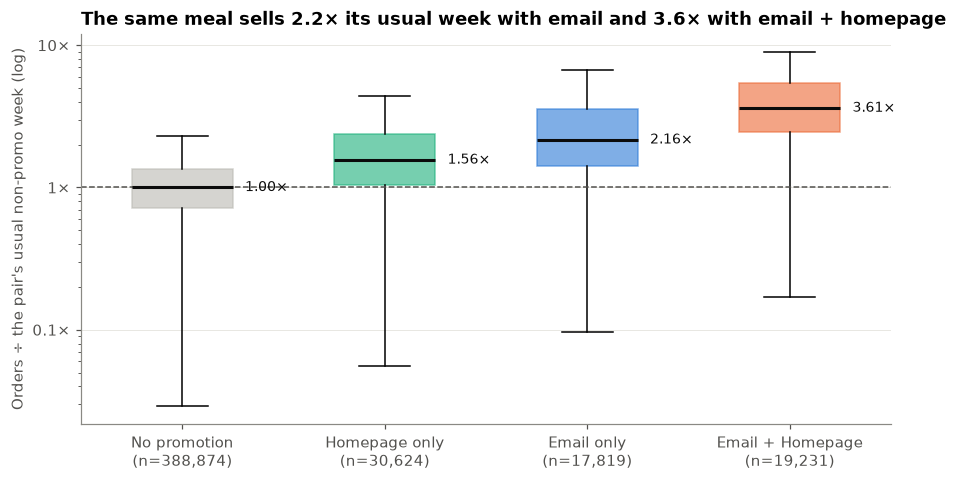

In [39]:
order = ["No promotion", "Homepage only", "Email only", "Email + Homepage"]
rel = df.dropna(subset=["pair_base"])
data = [rel.loc[rel.promo_type == k, "rel_orders"].clip(upper=rel.rel_orders.quantile(.995)) for k in order]
meds = [d.median() for d in data]
fig, ax = plt.subplots(figsize=(9.5, 4.6))
bp = ax.boxplot(data, patch_artist=True, widths=0.5, showfliers=False,
                medianprops=dict(color=INK, lw=2))
ax.set_xticks(range(1, len(order)+1), [f"{k}\n(n={len(d):,})" for k, d in zip(order, data)])
for patch, col in zip(bp["boxes"], [GREY, AQUA, BLUE, ORANGE]): patch.set_facecolor(col); patch.set_alpha(0.6); patch.set_edgecolor(col)
for i, m in enumerate(meds, 1): ax.text(i + 0.31, m, f"{m:.2f}×", va="center", fontsize=9, color=INK)
ax.axhline(1, color=INK2, lw=1, ls="--")
ax.set_yscale("log"); ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:g}×"))
ax.set_title(f"The same meal sells {meds[2]:.1f}× its usual week with email and {meds[3]:.1f}× with email + homepage")
ax.set_ylabel("Orders ÷ the pair's usual non-promo week (log)"); ax.grid(axis="x", visible=False)
fig.savefig(FIG/"04_promo_boxplot.png"); plt.show()

**التفسير:** ضمن نفس الوجبة في نفس المركز، تُباع الوجبات في الأسابيع التي تُقدم فيها عروض ترويجية بشكل ملحوظ أكثر، ويبقى هذا الفرق قائمًا حتى بعد تصحيح اختبارات المقارنة المتعددة في نسبة كبيرة من الأزواج. يُظهر نموذج التأثيرات الثابتة ارتباط العرض الترويجي بعد تثبيت الخصم، وزوج الوجبة والمركز، والأسبوع، وهو الرقم الذي يُعتمد عليه. هناك تحذيران يحدّان من مدى دقة هذا التفسير. أولًا، من المحتمل أن يكون قسم التسويق هو من اختار الوجبات التي سيتم الترويج لها وتوقيتها، لذا قد تكون العروض الترويجية موجهة إلى أسابيع كانت ستشهد إقبالًا قويًا على أي حال (انحياز الاختيار). ثانيًا، لا تُظهر البيانات ما إذا كانت الطلبات المُروّجة تمثل طلبًا جديدًا أم طلبات مُستمدة من وجبات أخرى أو أسابيع لاحقة. يُعد اختبار التحقق العشوائي الطريقة الوحيدة لتحويل هذه الارتباطات إلى علاقة سببية.

## س5. كيف يرتبط الخصم بالطلب؟

In [40]:
rho_all, p_all = stats.spearmanr(df.discount_pct, df.num_orders)
nop = df[df.any_promo == 0]
rho_nop, p_nop = stats.spearmanr(nop.discount_pct, nop.num_orders)
rho_rel, p_rel = stats.spearmanr(rel.discount_pct, rel.rel_orders)
within = []
for _, g in df.groupby(["center_id", "meal_id"]):
    if len(g) >= 20 and g.discount_pct.nunique() > 5:
        within.append(stats.spearmanr(g.discount_pct, g.num_orders)[0])
within = pd.Series(within).dropna()
bins = [-1, 0, 0.05, 0.10, 0.20, 0.30, 1]
lbl = ["≤0%", "0–5%", "5–10%", "10–20%", "20–30%", ">30%"]
rel = rel.assign(disc_band=pd.cut(rel.discount_pct, bins=bins, labels=lbl))
band = rel.groupby(["disc_band", "any_promo"], observed=True)["rel_orders"].agg(["median", "size"]).unstack()
RESULTS["q5"] = dict(spearman_pooled=float(rho_all), p_pooled=float(p_all), spearman_no_promo=float(rho_nop),
                     spearman_rel_orders=float(rho_rel), within_pair_median_rho=float(within.median()),
                     within_pair_share_positive=float((within > 0).mean()), pairs=len(within),
                     band_median_no_promo={str(k): float(v) for k, v in band[("median", 0)].items()},
                     band_median_promo={str(k): float(v) for k, v in band[("median", 1)].dropna().items()})
print(f"Spearman pooled raw orders: rho={rho_all:.3f}  |  no-promo rows: rho={rho_nop:.3f}  |  pair-relative orders: rho={rho_rel:.3f}")
print(f"Within-pair Spearman: median rho={within.median():.3f}, positive in {(within>0).mean():.0%} of {len(within):,} pairs")
band

Spearman pooled raw orders: rho=0.122  |  no-promo rows: rho=0.023  |  pair-relative orders: rho=0.286
Within-pair Spearman: median rho=0.260, positive in 89% of 3,556 pairs


median          size       
any_promo      0     1       0      1
disc_band                            
≤0%        0.997 1.255  216490  10371
0–5%       0.996 1.380  108241   6745
5–10%      0.933 1.666    1394   3250
10–20%     1.165 1.929   35984  16005
20–30%     1.278 2.800   15088  14740
>30%       1.310 4.074   11677  16563

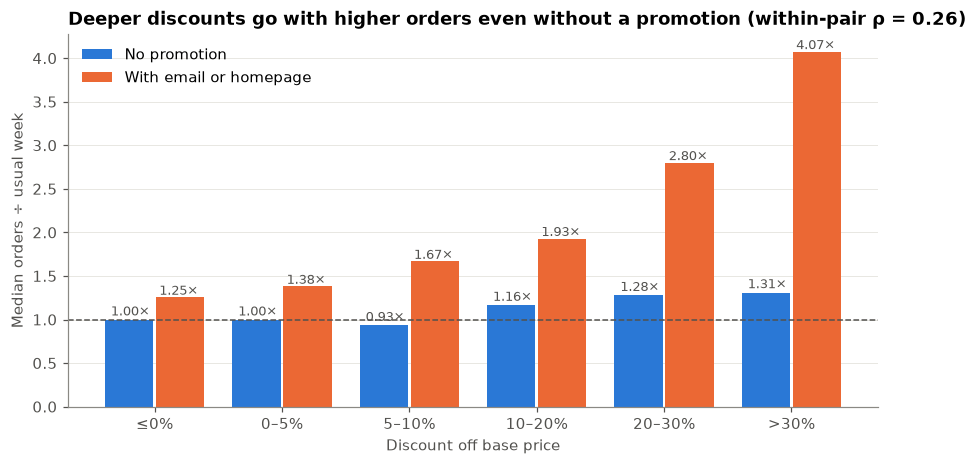

In [41]:
fig, ax = plt.subplots(figsize=(9.5, 4.4))
x = np.arange(len(lbl)); w = 0.38
m0 = band[("median", 0)].reindex(lbl).values; m1 = band[("median", 1)].reindex(lbl).values
ax.bar(x - w/2 - 0.01, m0, w, color=BLUE, label="No promotion")
ax.bar(x + w/2 + 0.01, m1, w, color=ORANGE, label="With email or homepage")
for xi, v in zip(x - w/2, m0): ax.text(xi, v + 0.05, f"{v:.2f}×", ha="center", fontsize=8.5, color=INK2)
for xi, v in zip(x + w/2, m1):
    if not np.isnan(v): ax.text(xi, v + 0.03, f"{v:.2f}×", ha="center", fontsize=8.5, color=INK2)
ax.axhline(1, color=INK2, lw=1, ls="--")
ax.set_xticks(x, lbl); ax.set_xlabel("Discount off base price"); ax.set_ylabel("Median orders ÷ usual week")
ax.legend(frameon=False, loc="upper left"); ax.grid(axis="x", visible=False)
ax.set_title(f"Deeper discounts go with higher orders even without a promotion (within-pair ρ = {within.median():.2f})")
fig.savefig(FIG/"05_discount_vs_orders.png"); plt.show()

معامل سبيرمان المجمع للطلبات الأولية ضعيف لأنه يخلط بين الوجبات الرخيصة ذات الكميات الكبيرة والوجبات باهظة الثمن ذات الكميات الصغيرة. عند مقارنة كل صف مع خط الأساس الخاص به في مركز الوجبات، يصبح الارتباط أوضح وإيجابيًا، وينطبق هذا حتى على الصفوف التي لا تشملها العروض الترويجية، مما يعني أن الخصم مرتبط بالطلب بشكل مباشر وليس مجرد أثر جانبي للعروض الترويجية. تم تحديد تغييرات الأسعار في هذه البيانات من قبل الشركة، لذا قد تستجيب للطلب المتوقع؛ يصف المعامل الحركة المشتركة، وليس مرونة السعر.

## س6. ما هي الوجبات التي تشهد طلباً متقلباً وتحتاج إلى المزيد من المخزون الاحتياطي؟

In [42]:
mw = df.groupby(["meal_id", "week"])["num_orders"].sum().reset_index()
vol = mw.groupby("meal_id")["num_orders"].agg(mean="mean", std="std", weeks="count").reset_index()
vol["cv"] = vol["std"] / vol["mean"]
pcv = df.groupby(["center_id", "meal_id"])["num_orders"].agg(["mean", "std", "count"])
pcv = pcv[pcv["count"] >= 20]; pcv["cv"] = pcv["std"] / pcv["mean"]
vol = vol.merge(pcv.groupby("meal_id")["cv"].median().rename("median_center_cv"), on="meal_id").merge(meals, on="meal_id")
vol_cut, cv_cut = vol["mean"].median(), vol["cv"].median()
vol["segment"] = np.select([(vol["mean"] >= vol_cut) & (vol.cv >= cv_cut), (vol["mean"] >= vol_cut), (vol.cv >= cv_cut)],
                           ["High volume / volatile", "High volume / stable", "Low volume / volatile"], "Low volume / stable")
# safety-stock index: extra units for ~95% service ≈ 1.65·σ (weekly, normal approx) — indicative only
vol["safety_units_95"] = 1.65 * vol["std"]
vol = vol.sort_values(["segment", "safety_units_95"], ascending=[True, False])
hv = vol[vol.segment == "High volume / volatile"].sort_values("safety_units_95", ascending=False)
RESULTS["q6"] = dict(median_meal_cv=float(cv_cut), median_center_meal_cv=float(pcv.cv.median()),
                     n_high_vol_volatile=len(hv), high_vol_volatile_meals=hv[["meal_id", "category", "cuisine", "mean", "cv", "safety_units_95"]].round(3).to_dict(orient="records"),
                     share_orders_high_vol_volatile=float(meal.set_index("meal_id").loc[hv.meal_id, "orders"].sum()/meal.orders.sum()),
                     segment_counts=vol.segment.value_counts().to_dict())
print(f"median meal-level CV = {cv_cut:.2f}; median centre-meal CV = {pcv.cv.median():.2f}")
print(f"{len(hv)} meals are high-volume AND volatile, carrying {RESULTS['q6']['share_orders_high_vol_volatile']:.0%} of all orders")
hv.head(12)

median meal-level CV = 0.46; median centre-meal CV = 0.63
14 meals are high-volume AND volatile, carrying 49% of all orders


,meal_id,mean,std,weeks,cv,median_center_cv,category,cuisine,segment,safety_units_95
30,2290,"67,381.400","60,641.916",145,0.900,0.972,Rice Bowl,Indian,High volume / volatile,"100,059.162"
25,1971,"39,507.724","43,605.509",145,1.104,1.257,Sandwich,Italian,High volume / volatile,"71,949.090"
16,1754,"47,021.097","41,698.021",145,0.887,0.982,Sandwich,Italian,High volume / volatile,"68,801.735"
35,2490,"29,673.000","27,959.324",125,0.942,0.968,Salad,Italian,High volume / volatile,"46,132.885"
15,1727,"32,661.979","26,274.639",145,0.804,0.920,Rice Bowl,Indian,High volume / volatile,"43,353.155"
1,1109,"43,915.676","24,620.200",145,0.561,0.629,Rice Bowl,Indian,High volume / volatile,"40,623.329"
48,2826,"35,104.159","17,059.038",145,0.486,0.594,Sandwich,Italian,High volume / volatile,"28,147.413"
24,1962,"22,315.724","15,268.033",145,0.684,0.747,Pizza,Continental,High volume / volatile,"25,192.254"
39,2569,"25,848.054","12,458.754",129,0.482,0.555,Salad,Italian,High volume / volatile,"20,556.944"
41,2581,"16,544.828","11,934.251",145,0.721,0.812,Pizza,Continental,High volume / volatile,"19,691.514"


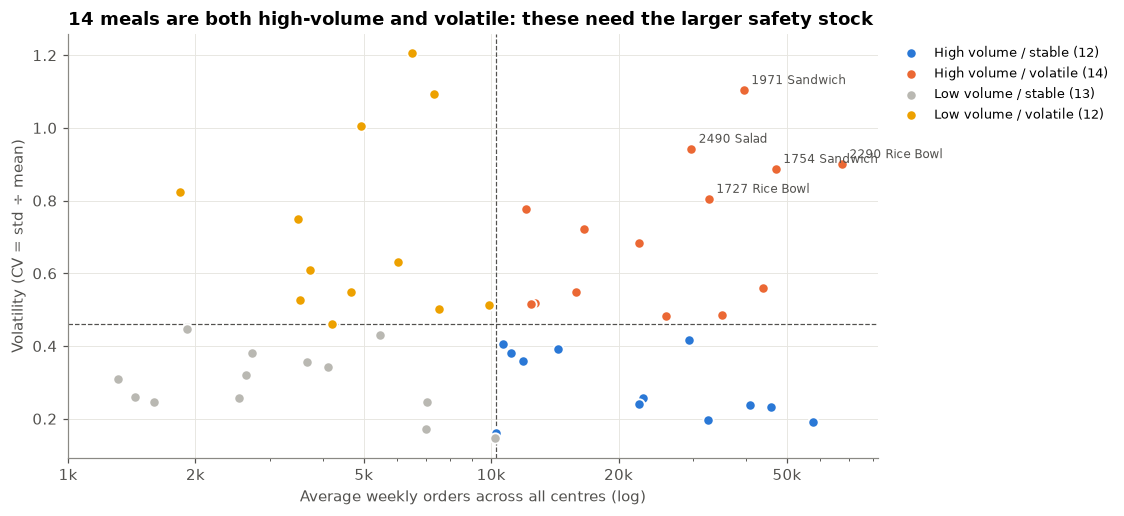

In [43]:
seg_col = {"High volume / volatile": ORANGE, "High volume / stable": BLUE, "Low volume / volatile": YELLOW, "Low volume / stable": GREY}
fig, ax = plt.subplots(figsize=(9.5, 5))
for s, g in vol.groupby("segment"):
    ax.scatter(g["mean"]/1e3, g.cv, s=46, color=seg_col[s], label=f"{s} ({len(g)})", edgecolor="white", lw=1.2, zorder=3)
ax.axvline(vol_cut/1e3, color=INK2, lw=0.8, ls="--"); ax.axhline(cv_cut, color=INK2, lw=0.8, ls="--")
for _, r in hv.head(5).iterrows():
    ax.annotate(f"{int(r.meal_id)} {r.category}", (r["mean"]/1e3, r.cv), xytext=(5, 4), textcoords="offset points", fontsize=8, color=INK2)
ax.set_xscale("log"); ax.set_xticks([1, 2, 5, 10, 20, 50]); ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:g}k")); ax.xaxis.set_minor_formatter(mtick.NullFormatter())
ax.set_xlabel("Average weekly orders across all centres (log)"); ax.set_ylabel("Volatility (CV = std ÷ mean)")
ax.set_title(f"{len(hv)} meals are both high-volume and volatile: these need the larger safety stock")
ax.legend(frameon=False, fontsize=8.5, loc="upper left", bbox_to_anchor=(1.01, 1))
fig.savefig(FIG/"06_volatility_matrix.png"); plt.show()

يُقاس التقلب بناءً على الأسابيع المُسجلة فقط؛ ولا تُعتبر الأسابيع التي لا يوجد بها سجل بمثابة صفر. يفترض رقم مخزون الأمان 1.65·σ طلبًا أسبوعيًا طبيعيًا تقريبًا وأسابيع مستقلة، وهو ما يخالفه الطلب المنحرف والمدفوع بالعروض الترويجية، لذا فهو مؤشر تصنيف لتحديد أماكن الاحتفاظ بمزيد من المخزون الاحتياطي، وليس مستوى مخزون يُطلب. يتم تصدير نسخة على مستوى المركز (بنفس الحساب لكل مركز ووجبة) إلى برنامج Power BI للمديرين الذين يقومون فعليًا بتقديم الطلبات.

## اختياري: توقعات الطلب لمدة 10 أسابيع (التعلم الآلي)

تقوم الشركة بطلب المكونات مسبقًا، لذا يجب ألا تعتمد التوقعات على الطلبات الفعلية للأسبوع الماضي لأسابيع لم يتم الاطلاع عليها بعد. ولذلك، تستخدم الميزات فترات تأخير **10 أسابيع أو أكثر**، وهي جميعها معروفة عند وضع خطة الأسابيع العشرة، بالإضافة إلى مؤشرات الأسعار والعروض الترويجية المخطط لها (يوفر ملف الاختبار هذه المؤشرات للأسابيع من 146 إلى 155).

فترة التحقق: الأسابيع من 136 إلى 145. خطان أساسيان: (أ) الأسبوع الأخير المعروف (135) بعد ترحيله، وهو المقارنة العادلة لأفق زمني مدته 10 أسابيع؛ (ب) الطلبات الفعلية للأسبوع السابق (فترة التأخير -1)، والتي يطلبها الموجز ولكنها تحتوي على معلومات غير متوفرة لدى النموذج، لذا فهي متفائلة.

In [44]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

full = pd.concat([df[train.columns].assign(split="train"), test.assign(num_orders=np.nan, split="test")], ignore_index=True)
full = full.merge(meals, on="meal_id").merge(centers, on="center_id")
key = full[["center_id", "meal_id", "week", "num_orders"]]
for L in (10, 11, 12, 13, 14, 15, 20, 26, 52):
    full = full.merge(key.assign(week=key.week + L).rename(columns={"num_orders": f"lag{L}"}), on=["center_id", "meal_id", "week"], how="left")
full["lag_mean_10_15"] = full[[f"lag{L}" for L in range(10, 16)]].mean(axis=1)
full["discount_pct"] = (full.base_price - full.checkout_price) / full.base_price
full["week_mod52"] = full.week % 52
for c in ["category", "cuisine", "center_type"]: full[c] = full[c].astype("category").cat.codes
feats = ["checkout_price", "base_price", "discount_pct", "emailer_for_promotion", "homepage_featured", "center_id", "meal_id",
         "category", "cuisine", "center_type", "op_area", "city_code", "region_code", "week_mod52",
         "lag10", "lag11", "lag12", "lag13", "lag14", "lag15", "lag20", "lag26", "lag52", "lag_mean_10_15"]
full[feats] = full[feats].fillna(-1)
print(f"rows in modelling frame: {len(full):,} (train {int((full.split=='train').sum()):,} + test {int((full.split=='test').sum()):,})")

tr = full[(full.split == "train") & (full.week <= 135)]; ho = full[(full.split == "train") & (full.week.between(136, 145))]
rf = RandomForestRegressor(n_estimators=80, max_depth=22, min_samples_leaf=3, max_features=0.5, max_samples=0.6, n_jobs=-1, random_state=42, oob_score=True)
rf.fit(tr[feats], np.log1p(tr.num_orders))
# A log target predicts the median, which under-shoots totals for skewed demand. Duan smearing on out-of-bag residuals corrects the level.
smear = float(np.mean(np.exp(np.log1p(tr.num_orders).values - rf.oob_prediction_)))
print(f"smearing factor (OOB) = {smear:.3f}")
ho_pred_rf_raw = np.expm1(rf.predict(ho[feats])); ho_pred_rf = np.exp(rf.predict(ho[feats])) * smear - 1
lr = LinearRegression().fit(tr[feats], np.log1p(tr.num_orders)); ho_pred_lr = np.expm1(lr.predict(ho[feats]))

last = df[df.week <= 135].sort_values("week").groupby(["center_id", "meal_id"])["num_orders"].last().rename("naive_last")
ho = ho.merge(last, on=["center_id", "meal_id"], how="left")
ho["naive_last"] = ho.naive_last.fillna(df[df.week <= 135].num_orders.median())
lag1 = key.assign(week=key.week + 1).rename(columns={"num_orders": "lag1"})
ho = ho.merge(lag1, on=["center_id", "meal_id", "week"], how="left"); ho["lag1"] = ho.lag1.fillna(ho.naive_last)
ho["pred_rf"], ho["pred_rf_raw"], ho["pred_lr"] = ho_pred_rf, ho_pred_rf_raw, ho_pred_lr
mae = {"Random Forest (10-wk horizon)": mean_absolute_error(ho.num_orders, ho.pred_rf),
       "Random Forest, no level correction": mean_absolute_error(ho.num_orders, ho.pred_rf_raw),
       "Linear Regression on log orders": mean_absolute_error(ho.num_orders, ho.pred_lr),
       "Naive: week 135 carried forward": mean_absolute_error(ho.num_orders, ho.naive_last),
       "Naive: previous week actual (lag-1, optimistic)": mean_absolute_error(ho.num_orders, ho.lag1)}
mae_s = pd.Series(mae).sort_values()
wk_err = ho.groupby("week")[["num_orders", "pred_rf", "pred_rf_raw", "naive_last"]].sum()
RESULTS["ml"] = dict(mae={k: float(v) for k, v in mae.items()},
                     rf_vs_naive_last=float(1 - mae["Random Forest (10-wk horizon)"]/mae["Naive: week 135 carried forward"]),
                     rf_vs_lag1=float(1 - mae["Random Forest (10-wk horizon)"]/mae["Naive: previous week actual (lag-1, optimistic)"]),
                     weekly_total_mape_rf=float((wk_err.pred_rf - wk_err.num_orders).abs().div(wk_err.num_orders).mean()),
                     weekly_total_mape_rf_raw=float((wk_err.pred_rf_raw - wk_err.num_orders).abs().div(wk_err.num_orders).mean()),
                     total_bias_rf=float(wk_err.pred_rf.sum()/wk_err.num_orders.sum()-1), smear=smear,
                     weekly_total_mape_naive=float((wk_err.naive_last - wk_err.num_orders).abs().div(wk_err.num_orders).mean()),
                     holdout_rows=len(ho))
mae_s.to_frame("MAE (orders per row)")

rows in modelling frame: 489,121 (train 456,548 + test 32,573)
smearing factor (OOB) = 1.130


,MAE (orders per row)
"Random Forest, no level correction",68.271
Random Forest (10-wk horizon),69.842
"Naive: previous week actual (lag-1, optimistic)",79.311
Naive: week 135 carried forward,110.318
Linear Regression on log orders,206.784


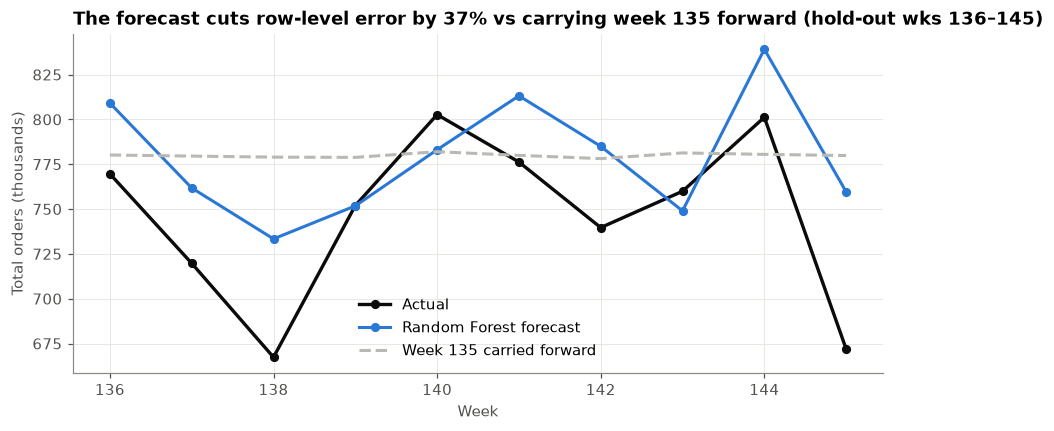

lag_mean_10_15          0.383
lag10                   0.104
lag11                   0.068
checkout_price          0.058
emailer_for_promotion   0.039
lag12                   0.033
lag13                   0.032
discount_pct            0.031
lag14                   0.028
base_price              0.028
dtype: float64

In [45]:
fig, ax = plt.subplots(figsize=(9.5, 4))
ax.plot(wk_err.index, wk_err.num_orders/1e3, color=INK, lw=2.2, marker="o", ms=5, label="Actual")
ax.plot(wk_err.index, wk_err.pred_rf/1e3, color=BLUE, lw=2, marker="o", ms=5, label="Random Forest forecast")
ax.plot(wk_err.index, wk_err.naive_last/1e3, color=GREY, lw=2, ls="--", label="Week 135 carried forward")
r = RESULTS["ml"]
ax.set_title(f"The forecast cuts row-level error by {r['rf_vs_naive_last']:.0%} vs carrying week 135 forward (hold-out wks 136–145)")
ax.set_xlabel("Week"); ax.set_ylabel("Total orders (thousands)"); ax.legend(frameon=False)
fig.savefig(FIG/"07_forecast_holdout.png"); plt.show()
imp = pd.Series(rf.feature_importances_, index=feats).sort_values(ascending=False).head(10); imp

In [46]:
# Refit on all 145 weeks and forecast the test weeks 146-155
rf.fit(full.loc[full.split == "train", feats], np.log1p(full.loc[full.split == "train", "num_orders"]))
te = full[full.split == "test"].copy(); smear_full = float(np.mean(np.exp(np.log1p(full.loc[full.split == "train", "num_orders"]).values - rf.oob_prediction_)))
te["forecast_orders"] = (np.exp(rf.predict(te[feats])) * smear_full - 1).round()
fc = te[["id", "week", "center_id", "meal_id", "checkout_price", "emailer_for_promotion", "homepage_featured", "forecast_orders"]]
fc.to_csv(PBI/"forecast_weeks_146_155.csv", index=False)
RESULTS["ml"]["forecast_total_146_155"] = float(fc.forecast_orders.sum())
print(f"forecast rows: {len(fc):,}; forecast total for weeks 146-155: {fc.forecast_orders.sum():,.0f}")
fc.groupby("week").forecast_orders.sum()

forecast rows: 32,573; forecast total for weeks 146-155: 8,506,943


week
146   724,427.000
147   821,836.000
148   753,434.000
149   754,702.000
150   949,133.000
151   915,091.000
152   965,614.000
153   945,242.000
154   886,657.000
155   790,807.000
Name: forecast_orders, dtype: float64

اختيار الحساسية: هل يتغير اثر العروض الترويجية اذا حذفنا الصفوف المتطرفة ؟

In [47]:
assert "q4" in RESULTS, "Run the Q4 cells first: use Kernel > Restart Kernel and Run All Cells"
rel_trim = df[(df.extreme_flag == 0) & (df.price_flag == 0)].dropna(subset=["pair_base"])
for flag in ["email", "home"]:
    a = rel_trim.loc[rel_trim[flag] == 1, "rel_orders"].median(); b = rel_trim.loc[rel_trim[flag] == 0, "rel_orders"].median()
    print(f"{flag:6s} pooled uplift without extreme/markup rows: {a/b-1:+.1%}  (full data: {RESULTS['q4']['tests'][flag]['pooled_uplift']:+.1%})")
print(f"rows used: {len(rel_trim):,}")

email  pooled uplift without extreme/markup rows: +188.2%  (full data: +190.7%)
home   pooled uplift without extreme/markup rows: +112.0%  (full data: +112.6%)
rows used: 455,858


## Export for Power BI and the report

In [48]:
fact = df[["id", "week", "center_id", "meal_id", "checkout_price", "base_price", "discount_pct", "email", "home", "any_promo",
           "promo_type", "num_orders", "revenue", "rel_orders", "price_flag", "extreme_flag"]].rename(
           columns={"email": "emailer_for_promotion", "home": "homepage_featured"})
fact.to_csv(PBI/"fact_orders.csv", index=False)
meals.to_csv(PBI/"dim_meal.csv", index=False)
centers.assign(center_label=lambda d: "C" + d.center_id.astype(str)).to_csv(PBI/"dim_center.csv", index=False)
pd.DataFrame({"week": range(1, 156)}).assign(split=lambda d: np.where(d.week <= 135, "Train", np.where(d.week <= 145, "Hold-out", "Forecast")),
                                             week_block=lambda d: ((d.week - 1)//13 + 1).map(lambda q: f"Block {q:02d}")).to_csv(PBI/"dim_week.csv", index=False)
vol.to_csv(PBI/"meal_volatility.csv", index=False)
pcv.reset_index().rename(columns={"mean": "avg_weekly_orders", "std": "std_weekly_orders", "count": "weeks_observed"}).assign(
    safety_units_95=lambda d: 1.65*d.std_weekly_orders).to_csv(PBI/"center_meal_volatility.csv", index=False)
pair_any.to_csv(PBI/"promo_pair_tests.csv", index=False)
fe_res.reset_index().rename(columns={"index": "term"}).to_csv(PBI/"promo_fixed_effects.csv", index=False)
ho[["week", "center_id", "meal_id", "num_orders", "pred_rf", "naive_last"]].to_csv(PBI/"forecast_holdout.csv", index=False)
(ROOT/"reports/results.json").write_text(json.dumps(RESULTS, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o)), encoding="utf-8")
print("fact rows exported:", f"{len(fact):,}", "| orders:", f"{fact.num_orders.sum():,}")
assert fact.num_orders.sum() == orders0
sorted(p.name for p in PBI.iterdir())

fact rows exported: 456,548 | orders: 119,557,485


['center_meal_volatility.csv',
 'dim_center.csv',
 'dim_meal.csv',
 'dim_week.csv',
 'fact_orders.csv',
 'forecast_holdout.csv',
 'forecast_weeks_146_155.csv',
 'meal_volatility.csv',
 'promo_fixed_effects.csv',
 'promo_pair_tests.csv']